In [1]:
# Download the Pokemon Image Dataset from Kaggle
import kagglehub
import os

path = kagglehub.dataset_download("hlrhegemony/pokemon-image-dataset")

print("Dataset Path:", path)
print("Exists:", os.path.exists(path))
print("Contents:", os.listdir(path)[:20])

100%|██████████| 57.9M/57.9M [00:00<00:00, 91.2MB/s]

Extracting files...


Dataset Path: /root/.cache/kagglehub/datasets/hlrhegemony/pokemon-image-dataset/versions/2
Exists: True
Contents: ['images']


In [2]:
print("HARSHAVARTHAN SB 24BAD033")

!pip install -q kagglehub transformers

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from PIL import Image
from sklearn.model_selection import train_test_split
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from transformers import pipeline

HARSHAVARTHAN SB 24BAD033


In [3]:
# ---------------- PART A : DATASET PREPARATION ----------------

print("HARSHAVARTHAN SB 24BAD033")

import os
import numpy as np
from sklearn.model_selection import train_test_split

image_path = os.path.join(path, "images")

print("Image Path:", image_path)

data = {}

for name in os.listdir(image_path):
    folder = os.path.join(image_path, name)

    if os.path.isdir(folder):
        imgs = []

        for f in os.listdir(folder):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                imgs.append(os.path.join(folder, f))

        # Use a lower threshold so we get enough classes
        if len(imgs) >= 2:
            data[name] = imgs

# Sort by number of images (descending) and pick top 10 classes
data = sorted(data.items(), key=lambda x: len(x[1]), reverse=True)
data = data[:10]

classes = []
files = []
labels = []

for i in range(len(data)):
    name = data[i][0]
    imgs = data[i][1]

    classes.append(name)

    for f in imgs:
        files.append(f)
        labels.append(i)

files = np.array(files)
labels = np.array(labels)

print("Number of Classes:", len(classes))
print("Total Images:", len(files))
print("Selected Classes:", classes)

# Split: 70% train, 15% validation, 15% test
x_train, x_temp, y_train, y_temp = train_test_split(
    files,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training Images:", len(x_train))
print("Validation Images:", len(x_val))
print("Testing Images:", len(x_test))

HARSHAVARTHAN SB 24BAD033
Image Path: /root/.cache/kagglehub/datasets/hlrhegemony/pokemon-image-dataset/versions/2/images
Number of Classes: 10
Total Images: 63
Selected Classes: ['Venusaur', 'Necrozma', 'Genesect', 'Vivillon', 'Darmanitan', 'Florges', 'Alakazam', 'Aerodactyl', 'Gengar', 'Unown']
Training Images: 44
Validation Images: 9
Testing Images: 10


In [4]:
print("HARSHAVARTHAN SB 24BAD033")
# ---------------- PART B : TRANSFER LEARNING ----------------

size = (224, 224)
batch = 16

def load_images(x, y):
    """Load images from file paths, preprocess them for ResNet-50."""
    images = []
    labels_out = []

    for i in range(len(x)):
        try:
            img = tf.keras.utils.load_img(x[i], target_size=size)
            img = tf.keras.utils.img_to_array(img)
            img = preprocess_input(img)
            images.append(img)
            labels_out.append(y[i])
        except Exception as e:
            print(f"Skipping {x[i]}: {e}")

    return np.array(images), np.array(labels_out)

# Load all image data into numpy arrays
X_train_data, Y_train_data = load_images(x_train, y_train)
X_val_data, Y_val_data = load_images(x_val, y_val)
X_test_data, Y_test_data = load_images(x_test, y_test)

print(f"Training data shape: {X_train_data.shape}")
print(f"Validation data shape: {X_val_data.shape}")
print(f"Test data shape: {X_test_data.shape}")

# Create tf.data datasets with shuffling for training
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train_data, Y_train_data)
).shuffle(buffer_size=len(X_train_data), seed=42).batch(batch)

# No shuffling for validation and test
val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val_data, Y_val_data)
).batch(batch)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test_data, Y_test_data)
).batch(batch)

# Load pre-trained ResNet-50 (without the top classification layer)
base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the feature extraction layers
base.trainable = False

num_classes = len(classes)

# Build the classification model
model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

print("\nResNet-50 model created")
print("Feature extraction layers frozen")
print(f"Number of output classes: {num_classes}")

HARSHAVARTHAN SB 24BAD033
Training data shape: (44, 224, 224, 3)
Validation data shape: (9, 224, 224, 3)
Test data shape: (10, 224, 224, 3)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,826 (91.99 MB)

 Trainable params: 527,114 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


ResNet-50 model created
Feature extraction layers frozen
Number of output classes: 10


HARSHAVARTHAN SB 24BAD033
Epoch 1/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 43s 9s/step - accuracy: 0.0455 - loss: 4.3105 - val_accuracy: 0.0000e+00 - val_loss: 3.1769
Epoch 2/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.1591 - loss: 3.3912 - val_accuracy: 0.1111 - val_loss: 2.6339
Epoch 3/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step - accuracy: 0.0682 - loss: 2.9354 - val_accuracy: 0.2222 - val_loss: 2.2741
Epoch 4/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.2273 - loss: 2.5932 - val_accuracy: 0.3333 - val_loss: 2.0448
Epoch 5/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.3182 - loss: 1.7467 - val_accuracy: 0.5556 - val_loss: 1.8905
Epoch 6/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.5455 - loss: 1.3627 - val_accuracy: 0.5556 - val_loss: 1.7482
Epoch 7/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.6364 - loss: 1.2637 - val_accuracy: 0.5556 - val_loss: 1.5961
Epoch 8/15
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.6364 - loss: 1.2094 - val_

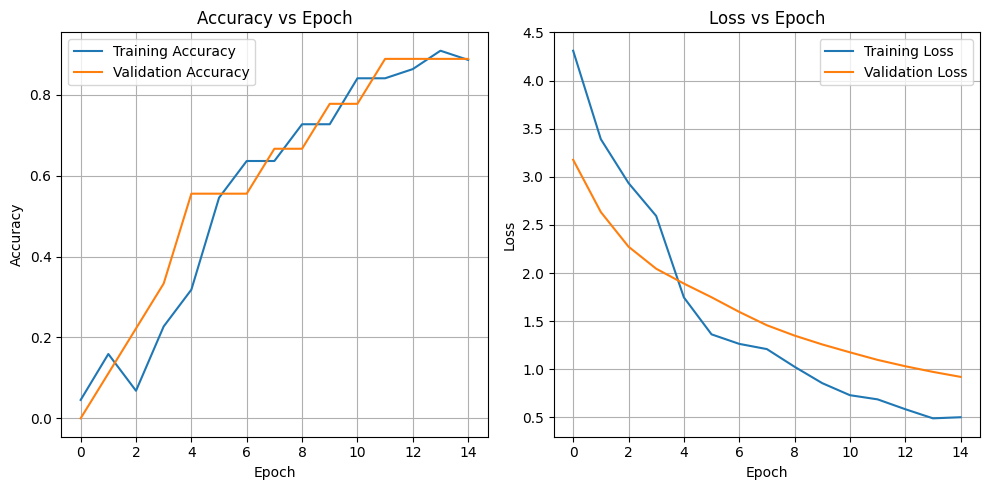

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

TRANSFER LEARNING PREDICTIONS
Actual: Necrozma         Predicted: Necrozma
Actual: Unown            Predicted: Unown
Actual: Gengar           Predicted: Gengar
Actual: Venusaur         Predicted: Darmanitan
Actual: Necrozma         Predicted: Necrozma
Actual: Venusaur         Predicted: Necrozma
Actual: Genesect         Predicted: Vivillon
Actual: Gengar           Predicted: Gengar
Actual: Darmanitan       Predicted: Darmanitan
Actual: Alakazam         Predicted: Alakazam


In [5]:
print("HARSHAVARTHAN SB 24BAD033")
# ---------------- PART C : TRAINING AND EVALUATION ----------------

# Early stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

# Evaluate on the test set
test_loss, test_acc = model.evaluate(test_ds)

train_acc = history.history["accuracy"][-1]
val_acc = history.history["val_accuracy"][-1]
train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

print("\nTRAINING RESULTS")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Validation Accuracy: {val_acc:.4f}")
print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Plot Accuracy vs Epoch
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid(True)

# Plot Loss vs Epoch
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Predictions on test set
pred = model.predict(test_ds)
pred_labels = np.argmax(pred, axis=1)

print("\nTRANSFER LEARNING PREDICTIONS")

for i in range(min(10, len(x_test))):
    print(
        f"Actual: {classes[Y_test_data[i]]:15s}  "
        f"Predicted: {classes[pred_labels[i]]}"
    )

HARSHAVARTHAN SB 24BAD033

Loading Hugging Face model...


config.json:   0%|          | 0.00/40.9k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  346MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/245 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Comparing predictions on 5 different Pokemon:

Image 1:
  Actual Class       : Necrozma
  ResNet-50 Prediction: Necrozma
  Hugging Face        : Necrozma (confidence: 0.962)
  Top HF predictions  : [('Necrozma', 0.962), ('Stakataka', 0.01), ('Stonjourner', 0.002)]

Image 2:
  Actual Class       : Unown
  ResNet-50 Prediction: Unown
  Hugging Face        : Unown (confidence: 0.996)
  Top HF predictions  : [('Unown', 0.996), ('Magnemite', 0.003), ('Castform', 0.0)]

Image 3:
  Actual Class       : Gengar
  ResNet-50 Prediction: Gengar
  Hugging Face        : Gengar (confidence: 0.328)
  Top HF predictions  : [('Gengar', 0.328), ('Mismagius', 0.087), ('Honchkrow', 0.052)]

Image 4:
  Actual Class       : Venusaur
  ResNet-50 Prediction: Darmanitan
  Hugging Face        : Clawitzer (confidence: 0.096)
  Top HF predictions  : [('Clawitzer', 0.096), ('Suicune', 0.077), ('Gyarados', 0.07)]

Image 5:
  Actual Class       : Genesect
  ResNet-50 Prediction: Vivillon
  Hugging Face        : Genes

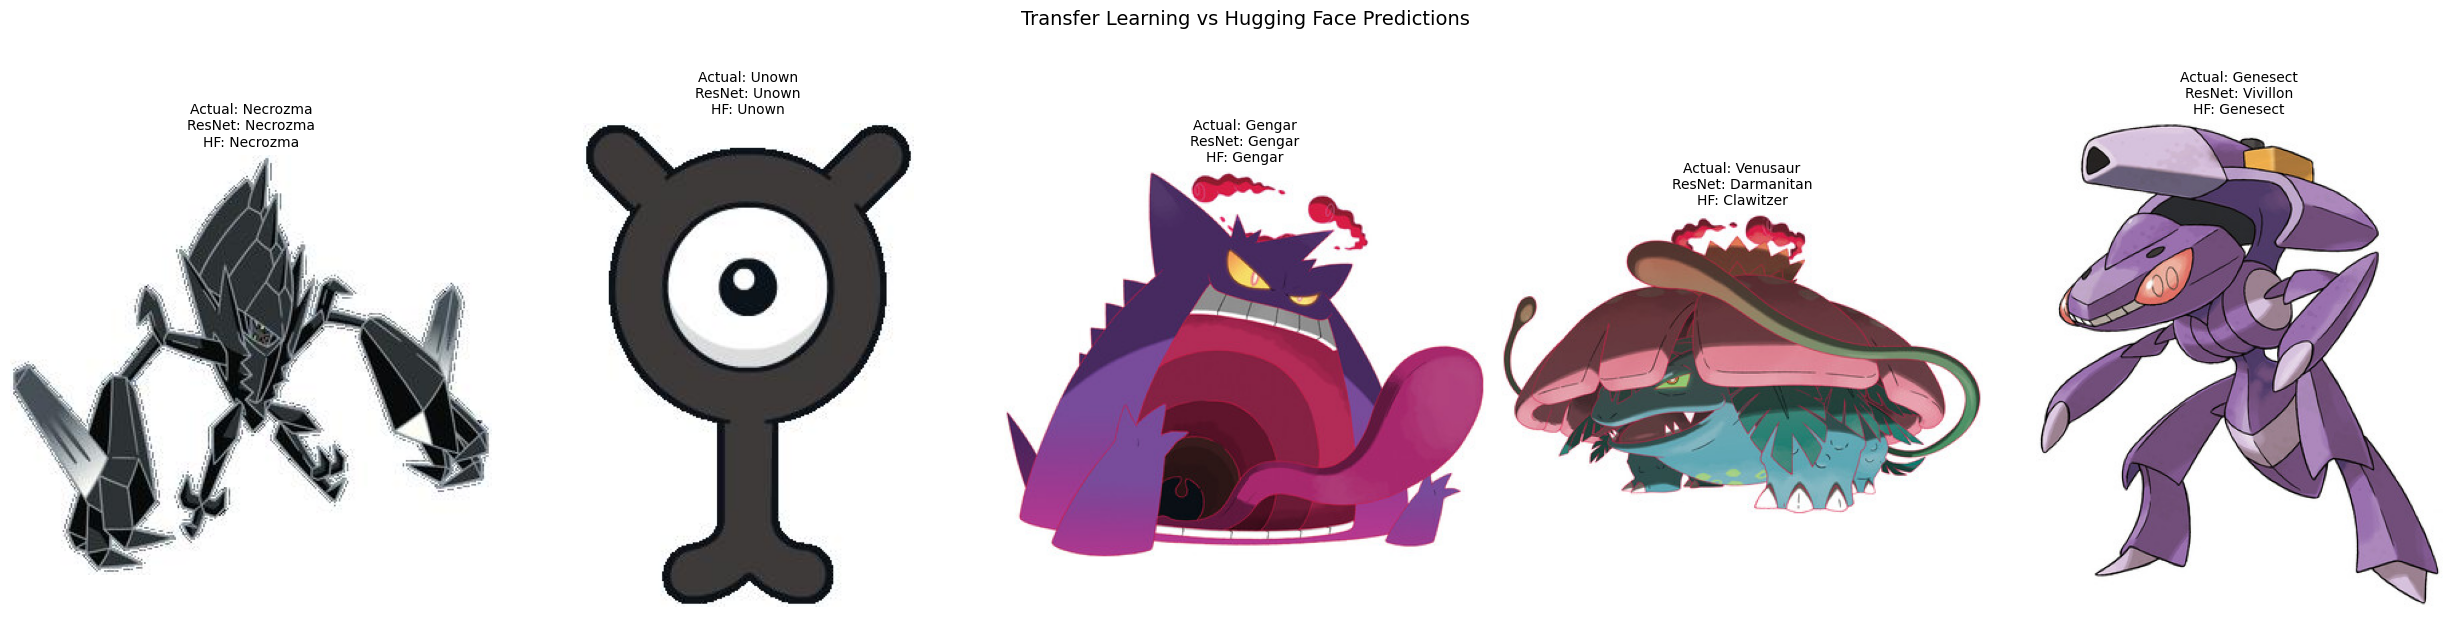


OBSERVATION
No major overfitting is observed from the training and validation accuracy.
The ResNet-50 model uses features learned from ImageNet.
The final classification layer is trained for the selected Pokemon classes.
The Hugging Face prediction is compared with the ResNet-50 prediction.


In [6]:
print("HARSHAVARTHAN SB 24BAD033")
# ---------------- PART D : HUGGING FACE MODEL ----------------

print("\nLoading Hugging Face model...")

hf_model = pipeline(
    "image-classification",
    model="imjeffhi/pokemon_classifier"
)

# Select up to 5 test images, each from a different Pokemon class
seen_classes = set()
sample_indices = []

for idx in range(len(x_test)):
    cls = y_test[idx]
    if cls not in seen_classes:
        seen_classes.add(cls)
        sample_indices.append(idx)
    if len(sample_indices) >= 5:
        break

num_samples = len(sample_indices)
print(f"Comparing predictions on {num_samples} different Pokemon:\n")

fig, axes = plt.subplots(1, num_samples, figsize=(5 * num_samples, 6))

if num_samples == 1:
    axes = [axes]

for j, idx in enumerate(sample_indices):
    img_path = x_test[idx]
    img = Image.open(img_path).convert("RGB")

    hf_result = hf_model(img)

    actual = classes[y_test[idx]]
    resnet_pred = classes[pred_labels[idx]]
    hf_pred = hf_result[0]["label"]
    hf_conf = round(hf_result[0]["score"], 3)

    print(f"Image {j+1}:")
    print(f"  Actual Class       : {actual}")
    print(f"  ResNet-50 Prediction: {resnet_pred}")
    print(f"  Hugging Face        : {hf_pred} (confidence: {hf_conf})")
    print(f"  Top HF predictions  : {[(r['label'], round(r['score'],3)) for r in hf_result[:3]]}")
    print()

    axes[j].imshow(img)
    axes[j].axis("off")
    axes[j].set_title(
        f"Actual: {actual}\n"
        f"ResNet: {resnet_pred}\n"
        f"HF: {hf_pred}",
        fontsize=10
    )

plt.suptitle("Transfer Learning vs Hugging Face Predictions", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ---------------- OBSERVATION ----------------

print("\nOBSERVATION")

if train_acc > val_acc + 0.1:
    print("The model shows signs of overfitting.")
else:
    print("No major overfitting is observed from the training and validation accuracy.")

print("The ResNet-50 model uses features learned from ImageNet.")
print("The final classification layer is trained for the selected Pokemon classes.")
print("The Hugging Face prediction is compared with the ResNet-50 prediction.")